# Лабораторная № 1. Линейная регрессия

Задача — предсказать `RiskScore`. Основная метрика — MSE. По заданию нужно получить меньше 25 на Kaggle, дополнительная цель — меньше 18.


In [1]:
from pathlib import Path
from itertools import combinations_with_replacement
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import Ridge, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.metrics import r2_score, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split, KFold, LeaveOneOut
from sklearn.preprocessing import StandardScaler, MinMaxScaler

SEED = 42
DATA_DIR = Path('data') if Path('data/train.csv').exists() else Path('lab1/data')
LAB_DIR = DATA_DIR.parent
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True})
train_raw = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
example = pd.read_csv(DATA_DIR / 'ex.csv')
display(pd.DataFrame({'выборка': ['train', 'test'],
                      'строк': [len(train_raw), len(test)],
                      'столбцов': [train_raw.shape[1], test.shape[1]]}))
display(train_raw.head())

,выборка,строк,столбцов
0,train,11017,35
1,test,5000,35


,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,...,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,RiskScore
0,2010-06-26,27.0,66829.0,549.0,17290.0,60.0,Divorced,1.0,Rent,1095.0,...,4.0,Employed,Associate,4.0,35067.0,0.257790,0.251465,508.970230,0.288013,66.176500
1,1996-09-23,55.0,172147.0,850.0,16110.0,36.0,Widowed,1.0,Mortgage,211.0,...,2.0,Employed,High School,33.0,27001.0,0.086110,0.093173,514.675859,0.050585,28.495737
2,2015-01-19,51.0,300000.0,850.0,38436.0,36.0,Married,0.0,Mortgage,546.0,...,3.0,Employed,Bachelor,28.0,278382.0,0.108436,0.115443,1268.276385,0.072571,34.488104
3,1981-05-12,25.0,34683.0,847.0,19186.0,48.0,Married,0.0,Other,153.0,...,3.0,Employed,High School,0.0,9224.0,0.100686,0.112822,498.505187,0.225415,36.910753
4,1995-05-07,55.0,300000.0,850.0,30437.0,48.0,Single,2.0,Rent,562.0,...,5.0,Employed,Bachelor,31.0,4502.0,0.110437,0.089037,756.035156,0.052721,31.347091


## 1. Подготовка данных

Удалим пропуски, дубликаты и ошибочные значения цели −9999999 и 10000000. Останется 9332 строки, которые разделим на обучение и проверку в отношении 80/20.

В тесте пропусков нет. Удаление неполных строк упрощает обработку, но может сместить выборку.


In [2]:
display(train_raw.isna().sum().rename('пропусков').to_frame().T)
display(train_raw['RiskScore'].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]))
display(train_raw.loc[train_raw['RiskScore'].abs() > 1000, 'RiskScore'].value_counts())
train_complete = train_raw.dropna().copy()
train_unique = train_complete.drop_duplicates().copy()
data = train_unique.loc[~train_unique['RiskScore'].isin([-9999999, 10000000])].reset_index(drop=True)
cleaning = pd.DataFrame({
    'этап': ['Исходные данные', 'Удалены строки с пропусками', 'Удалены дубликаты', 'Удалены ошибочные цели'],
    'осталось': [len(train_raw), len(train_complete), len(train_unique), len(data)]
})
display(cleaning)
assert test.isna().sum().sum() == 0
assert test['ID'].is_unique
assert set(data.columns) - {'RiskScore'} == set(test.columns) - {'ID'}

X = data.drop(columns='RiskScore')
y = data['RiskScore'].to_numpy(dtype=float)
train_ids, valid_ids = train_test_split(np.arange(len(data)), test_size=0.2, random_state=SEED)
X_train, X_valid = X.iloc[train_ids], X.iloc[valid_ids]
y_train, y_valid = y[train_ids], y[valid_ids]
eda = data.iloc[train_ids]
display(pd.Series({'обучение': len(train_ids), 'валидация': len(valid_ids), 'тест': len(test)}))

,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,...,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,RiskScore
пропусков,530,530,530,1031,1031,530,530,530,530,1031,...,530,530,530,530,1031,1031,530,530,530,530


count    1.048700e+04
mean    -2.569878e+04
std      1.431675e+06
min     -9.999999e+06
1%      -9.999999e+06
25%      3.256475e+01
50%      4.411876e+01
75%      6.535690e+01
99%      9.022040e+01
max      1.000000e+07
Name: RiskScore, dtype: float64

RiskScore
-9999999.0     121
 10000000.0     94
Name: count, dtype: int64

,этап,осталось
0,Исходные данные,11017
1,Удалены строки с пропусками,9986
2,Удалены дубликаты,9529
3,Удалены ошибочные цели,9332


обучение     7465
валидация    1867
тест         5000
dtype: int64

## 2. Анализ данных

Построим распределение цели, зависимости и корреляции на обучающей части.


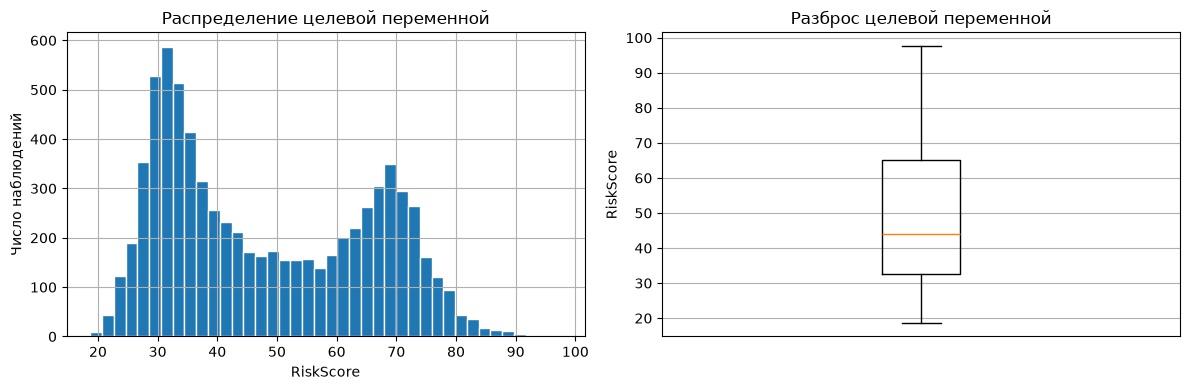

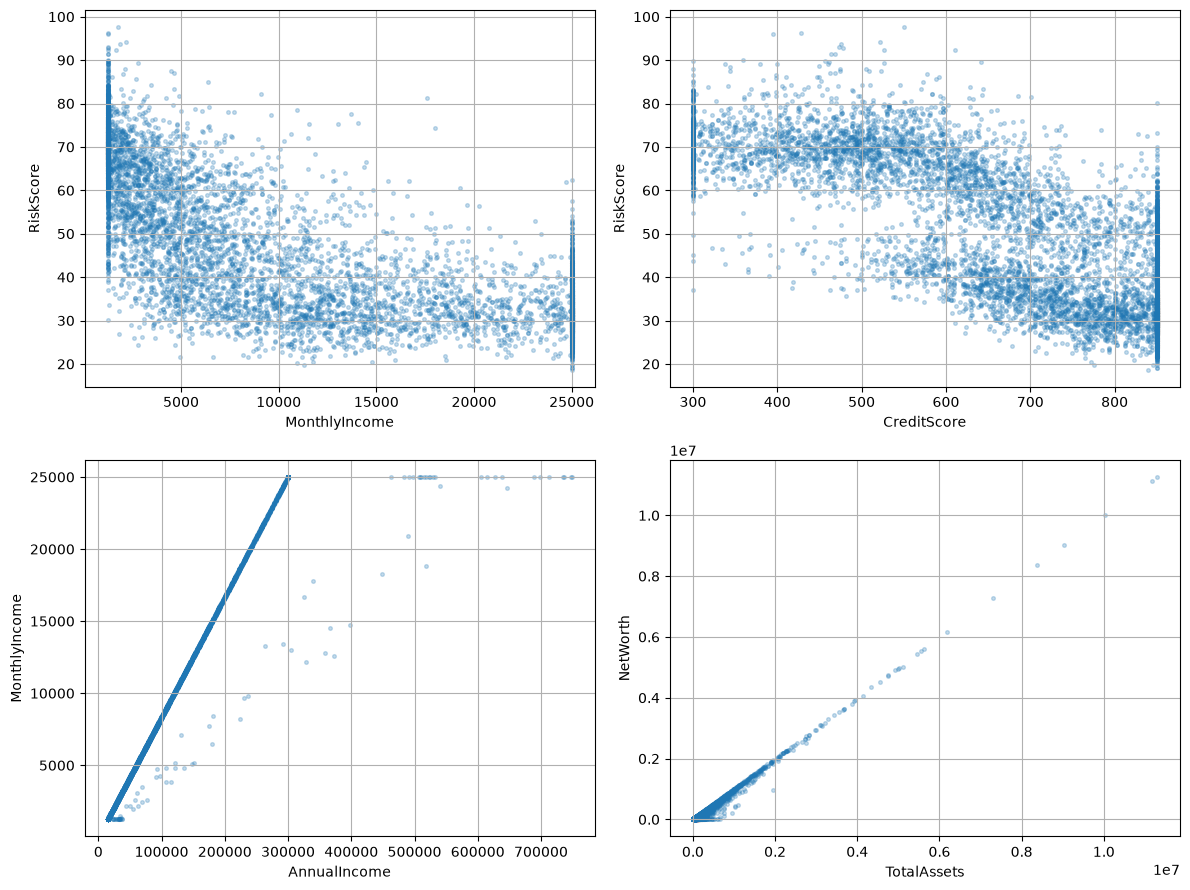

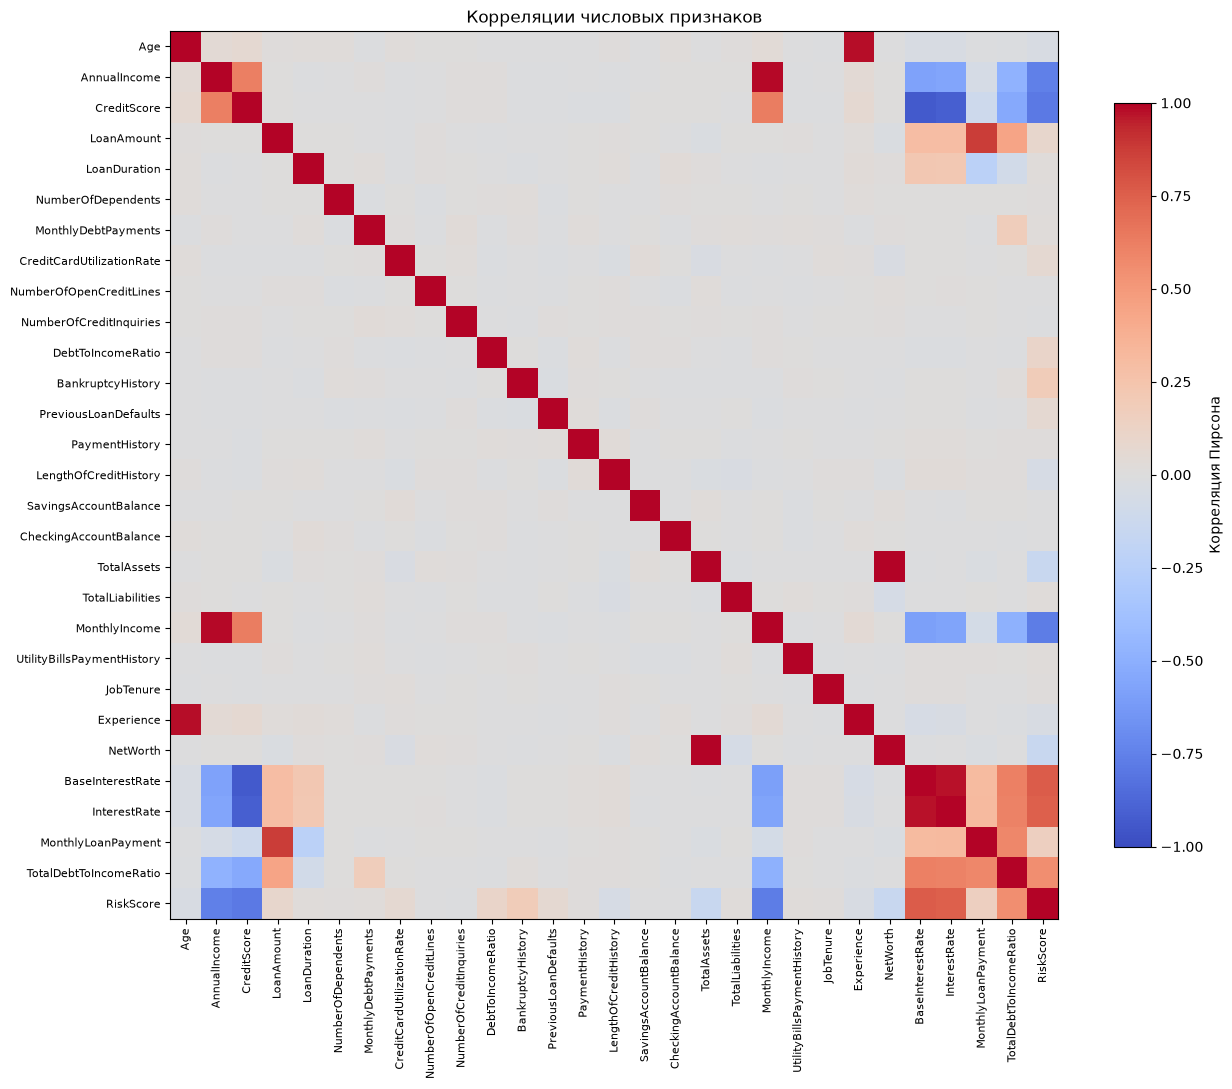

,RiskScore
CreditScore,-0.786353
MonthlyIncome,-0.768064
AnnualIncome,-0.756595
TotalAssets,-0.148148
NetWorth,-0.147229
LengthOfCreditHistory,-0.048157
Experience,-0.044597
Age,-0.042225
NumberOfCreditInquiries,-0.014981
CheckingAccountBalance,-0.007227


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(eda['RiskScore'], bins=40, edgecolor='white')
axes[0].set(xlabel='RiskScore', ylabel='Число наблюдений', title='Распределение целевой переменной')
axes[1].boxplot(eda['RiskScore'])
axes[1].set(ylabel='RiskScore', title='Разброс целевой переменной', xticks=[])
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
pairs = [('MonthlyIncome', 'RiskScore'), ('CreditScore', 'RiskScore'),
         ('AnnualIncome', 'MonthlyIncome'), ('TotalAssets', 'NetWorth')]
for ax, (left, right) in zip(axes.flat, pairs):
    ax.scatter(eda[left], eda[right], s=7, alpha=0.25)
    ax.set(xlabel=left, ylabel=right)
plt.tight_layout()
plt.show()

corr = eda.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(13, 11))
plot = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
ax.grid(False)
fig.colorbar(plot, ax=ax, label='Корреляция Пирсона', shrink=0.8)
ax.set_title('Корреляции числовых признаков')
plt.tight_layout()
plt.show()
display(corr['RiskScore'].drop('RiskScore').sort_values().to_frame())

### Выводы

- Доход и кредитный рейтинг отрицательно связаны с риском, ставка и долговая нагрузка — положительно. Это не доказывает причинную связь.
- Зависимость от дохода нелинейная, поэтому попробуем логарифмирование.
- Некоторые признаки сильно связаны между собой и имеют разные масштабы.


## 3. Нормализация

Z-score: $z=(x-\mu)/\sigma$.

Min-max: $z=(x-\min)/(\max-\min)$.

Параметры считаем только на обучении. Нулевой знаменатель заменяем на 1. Проверим результат со sklearn.


In [4]:
class Normalizer:
    def __init__(self, method='zscore'):
        self.method = method

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        if self.method == 'zscore':
            self.shift_ = X.mean(axis=0)
            self.scale_ = X.std(axis=0)
        elif self.method == 'minmax':
            self.shift_ = X.min(axis=0)
            self.scale_ = X.max(axis=0) - self.shift_
        else:
            raise ValueError('Неизвестный способ нормализации')
        self.scale_ = np.where(self.scale_ == 0, 1, self.scale_)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.shift_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


scale_example = np.array([[1, 10, 5], [2, 20, 5], [3, 40, 5]], dtype=float)
scale_new = np.array([[4, 50, 5]], dtype=float)
for method, reference in [('zscore', StandardScaler()), ('minmax', MinMaxScaler())]:
    own = Normalizer(method).fit(scale_example)
    reference.fit(scale_example)
    np.testing.assert_allclose(own.transform(scale_example), reference.transform(scale_example))
    np.testing.assert_allclose(own.transform(scale_new), reference.transform(scale_new))
    display(pd.DataFrame(own.transform(scale_example)).rename_axis(method))
print('Обе нормализации совпадают со sklearn, включая постоянный столбец и новые данные.')

,0,1,2
zscore,,,
0,-1.224745,-1.069045,0.0
1,0.000000,-0.267261,0.0
2,1.224745,1.336306,0.0


,0,1,2
minmax,,,
0,0.0,0.000000,0.0
1,0.5,0.333333,0.0
2,1.0,1.000000,0.0


Обе нормализации совпадают со sklearn, включая постоянный столбец и новые данные.


## 4. Метрики

$$MSE=\frac1n\sum_i(y_i-\hat y_i)^2,\qquad MAE=\frac1n\sum_i|y_i-\hat y_i|.$$

$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2},\qquad MAPE=\frac1n\sum_i\frac{|y_i-\hat y_i|}{\max(|y_i|,\varepsilon)}.$$

В таблицах MAPE показывается в процентах. Проверим метрики со sklearn, включая нулевую и постоянную цель.


In [5]:
def mse(y_true, y_pred):
    return float(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2))


def mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))


def r2(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    if len(y_true) < 2:
        return np.nan
    residual = np.sum((y_true - y_pred) ** 2)
    total = np.sum((y_true - y_true.mean()) ** 2)
    if total == 0:
        return 1.0 if residual == 0 else 0.0
    return float(1 - residual / total)


def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    denominator = np.maximum(np.abs(y_true), np.finfo(float).eps)
    return float(np.mean(np.abs(y_true - y_pred) / denominator))


def metrics(y_true, y_pred):
    return {'MSE': mse(y_true, y_pred), 'MAE': mae(y_true, y_pred),
            'R²': r2(y_true, y_pred), 'MAPE, %': 100 * mape(y_true, y_pred)}


metric_pairs = [(mse, mean_squared_error), (mae, mean_absolute_error),
                (r2, r2_score), (mape, mean_absolute_percentage_error)]
metric_cases = [([3., -0.5, 2., 7.], [2.5, 0., 2., 8.]),
                ([0., 1., -2.], [1., 1.5, -1.]),
                ([2., 2., 2.], [2., 2., 2.]),
                ([2., 2., 2.], [1., 2., 3.])]
metric_checks = []
for own, reference in metric_pairs:
    for actual, predicted in metric_cases:
        np.testing.assert_allclose(own(actual, predicted), reference(actual, predicted))
    actual, predicted = metric_cases[0]
    metric_checks.append({'метрика': own.__name__, 'своя': own(actual, predicted),
                          'sklearn': reference(actual, predicted)})
display(pd.DataFrame(metric_checks))
print('Проверены обычные данные, нулевая и постоянная цель.')

,метрика,своя,sklearn
0,mse,0.375000,0.375000
1,mae,0.500000,0.500000
2,r2,0.948608,0.948608
3,mape,0.327381,0.327381


Проверены обычные данные, нулевая и постоянная цель.


## 5. Линейная регрессия

Добавим столбец единиц для свободного члена. Прогноз: $\hat y=X_bw$.

- Аналитика: $w=X_b^+y$. Псевдообратная нужна для работы с зависимыми столбцами.
- GD: $w\leftarrow w-\eta\frac2nX_b^T(X_bw-y)$.
- SGD: обновление по одному объекту, шаг $\eta_t=\eta_0/\sqrt{t+1}$.

Для L2 добавим к MSE штраф $\alpha\sum_{j=1}^{d}w_j^2/n$. Свободный член не штрафуется.


In [6]:
class LinearRegression:
    def __init__(self, method='analytic', learning_rate=0.03, epochs=3000,
                 tol=1e-9, alpha=0.0, random_state=42):
        self.method = method
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.tol = tol
        self.alpha = alpha
        self.random_state = random_state

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        if self.alpha < 0:
            raise ValueError('alpha должна быть неотрицательной')
        X_b = np.column_stack([np.ones(len(X)), X])
        n, p = X_b.shape
        self.loss_history_ = []
        if self.method == 'analytic':
            if self.alpha == 0:
                self.weights_ = np.linalg.pinv(X_b) @ y
            else:
                penalty = np.eye(p)
                penalty[0, 0] = 0
                self.weights_ = np.linalg.solve(X_b.T @ X_b + self.alpha * penalty, X_b.T @ y)
        elif self.method in ('gd', 'sgd'):
            self.weights_ = np.zeros(p)
            rng = np.random.default_rng(self.random_state)
            for epoch in range(self.epochs):
                if self.method == 'gd':
                    error = X_b @ self.weights_ - y
                    penalty = self.weights_.copy()
                    penalty[0] = 0
                    gradient = 2 * (X_b.T @ error + self.alpha * penalty) / n
                    self.weights_ -= self.learning_rate * gradient
                else:
                    rate = self.learning_rate / np.sqrt(epoch + 1)
                    for i in rng.permutation(n):
                        error = X_b[i] @ self.weights_ - y[i]
                        penalty = self.weights_.copy()
                        penalty[0] = 0
                        gradient = 2 * error * X_b[i] + 2 * self.alpha * penalty / n
                        self.weights_ -= rate * gradient
                loss = mse(y, X_b @ self.weights_) + self.alpha * np.sum(self.weights_[1:] ** 2) / n
                if not np.isfinite(loss):
                    raise ValueError('Спуск расходится: уменьшите learning_rate')
                self.loss_history_.append(loss)
                if self.method == 'gd' and epoch > 0:
                    if abs(self.loss_history_[-2] - loss) < self.tol:
                        break
        else:
            raise ValueError('Неизвестный метод обучения')
        self.intercept_ = self.weights_[0]
        self.coef_ = self.weights_[1:]
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_


rng = np.random.default_rng(SEED)
toy_X = rng.normal(size=(100, 3))
toy_y = 4 + toy_X @ np.array([2., -3., 0.5])
for method in ['analytic', 'gd', 'sgd']:
    model = LinearRegression(method=method, learning_rate=0.02, epochs=500).fit(toy_X, toy_y)
    np.testing.assert_allclose(model.predict(toy_X), toy_y, atol=0.001)
dependent_X = np.column_stack([toy_X, 2 * toy_X[:, 0]])
model = LinearRegression().fit(dependent_X, toy_y)
reference = SklearnLinearRegression().fit(dependent_X, toy_y)
np.testing.assert_allclose(model.predict(dependent_X), reference.predict(dependent_X), atol=1e-8)
print('Три способа обучения восстановили известную линейную зависимость; проверены зависимые столбцы.')

Три способа обучения восстановили известную линейную зависимость; проверены зависимые столбцы.


## 6. Сравнение методов

Категории закодируем через one-hot. Уберём первый уровень, `ID` и дату. Нормализацию и кодирование обучаем только на train.

Сравним свои модели со sklearn на одном разбиении. Настройки двух реализаций SGD различаются, поэтому точного совпадения не ожидается.


,MSE,MAE,R²,"MAPE, %"
Своя аналитическая,49.495788,5.645597,0.834709,13.101285
Свой GD,49.508608,5.646779,0.834666,13.104949
Свой SGD,49.684908,5.664722,0.834077,13.147371
sklearn LinearRegression,49.495788,5.645597,0.834709,13.101285
sklearn SGDRegressor,49.860149,5.676236,0.833492,13.187670


,MSE,MAE,R²,"MAPE, %"
z-score,49.495788,5.645597,0.834709,13.101285
min-max,49.495788,5.645597,0.834709,13.101285


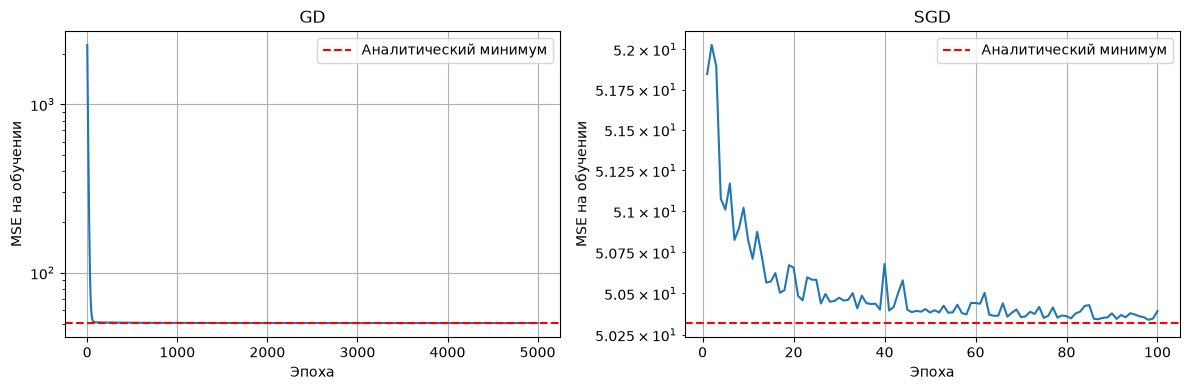

In [7]:
class BasicFeatures:
    def encode(self, frame):
        frame = frame.drop(columns=['ID', 'ApplicationDate'], errors='ignore')
        return pd.get_dummies(frame, columns=self.categories_, drop_first=True, dtype=float)

    def fit(self, frame):
        frame = frame.drop(columns=['ID', 'ApplicationDate'], errors='ignore')
        self.categories_ = frame.select_dtypes(exclude='number').columns.tolist()
        self.levels_ = {col: sorted(frame[col].unique()) for col in self.categories_}
        self.columns_ = self.encode_known(frame).columns
        return self

    def encode_known(self, frame):
        frame = frame.drop(columns=['ID', 'ApplicationDate'], errors='ignore').copy()
        for col in self.categories_:
            frame[col] = pd.Categorical(frame[col], categories=self.levels_[col])
        return self.encode(frame)

    def transform(self, frame):
        return self.encode_known(frame).reindex(columns=self.columns_, fill_value=0).astype(float)


basic = BasicFeatures().fit(X_train)
train_features = basic.transform(X_train)
valid_features = basic.transform(X_valid)
scaler = Normalizer().fit(train_features)
train_scaled = scaler.transform(train_features)
valid_scaled = scaler.transform(valid_features)

analytic = LinearRegression().fit(train_scaled, y_train)
gd = LinearRegression(method='gd', learning_rate=0.03, epochs=5000).fit(train_scaled, y_train)
sgd = LinearRegression(method='sgd', learning_rate=0.0005, epochs=100).fit(train_scaled, y_train)
sklearn_linear = SklearnLinearRegression().fit(train_scaled, y_train)
sklearn_sgd = SGDRegressor(loss='squared_error', penalty=None, max_iter=2000, tol=1e-6,
                           eta0=0.001, learning_rate='invscaling', random_state=SEED)
sklearn_sgd.fit(train_scaled, y_train)
models = {'Своя аналитическая': analytic, 'Свой GD': gd, 'Свой SGD': sgd,
          'sklearn LinearRegression': sklearn_linear, 'sklearn SGDRegressor': sklearn_sgd}
comparison = pd.DataFrame({name: metrics(y_valid, model.predict(valid_scaled))
                           for name, model in models.items()}).T
display(comparison)
np.testing.assert_allclose(analytic.predict(valid_scaled), sklearn_linear.predict(valid_scaled), atol=1e-6)
for own, reference in metric_pairs:
    np.testing.assert_allclose(own(y_valid, analytic.predict(valid_scaled)),
                               reference(y_valid, analytic.predict(valid_scaled)))

minmax = Normalizer('minmax').fit(train_features)
minmax_model = LinearRegression().fit(minmax.transform(train_features), y_train)
display(pd.DataFrame({'z-score': metrics(y_valid, analytic.predict(valid_scaled)),
                      'min-max': metrics(y_valid, minmax_model.predict(minmax.transform(valid_features)))}).T)
np.testing.assert_allclose(analytic.predict(valid_scaled),
                           minmax_model.predict(minmax.transform(valid_features)), atol=1e-6)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name, model in [(axes[0], 'GD', gd), (axes[1], 'SGD', sgd)]:
    ax.plot(np.arange(1, len(model.loss_history_) + 1), model.loss_history_)
    ax.axhline(mse(y_train, analytic.predict(train_scaled)), color='red', linestyle='--', label='Аналитический минимум')
    ax.set(xlabel='Эпоха', ylabel='MSE на обучении', title=name, yscale='log')
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Полиномиальные признаки

Аналитическое решение совпало со sklearn, GD и SGD дали близкие результаты. MSE базовой модели — около 49,5.

Применим `log1p` к денежным признакам и общей долговой нагрузке. Для восьми признаков добавим степени и произведения до третьей степени, для дохода и рейтинга — ещё четвёртую и пятую. Получится 204 признака.

Сравним обучение без штрафа и с L2 (`alpha=10`). Модель остаётся линейной по весам: $\hat y=w_0+\sum_jw_j\phi_j(x)$.


In [8]:
class PolynomialFeatures:
    def __init__(self):
        self.log_columns = ['AnnualIncome', 'MonthlyIncome', 'LoanAmount', 'MonthlyDebtPayments',
                            'SavingsAccountBalance', 'CheckingAccountBalance', 'TotalAssets',
                            'TotalLiabilities', 'NetWorth', 'MonthlyLoanPayment', 'TotalDebtToIncomeRatio']
        self.polynomial_columns = ['MonthlyIncome', 'CreditScore', 'DebtToIncomeRatio', 'NetWorth',
                                   'BankruptcyHistory', 'PreviousLoanDefaults', 'InterestRate',
                                   'TotalDebtToIncomeRatio']

    def logarithms(self, frame):
        frame = self.basic_.transform(frame)
        frame[self.log_columns] = np.log1p(frame[self.log_columns])
        return frame

    def fit(self, frame):
        self.basic_ = BasicFeatures().fit(frame)
        logged = self.logarithms(frame)
        self.base_scaler_ = Normalizer().fit(logged[self.polynomial_columns])
        self.combinations_ = []
        for degree in range(1, 4):
            self.combinations_.extend(combinations_with_replacement(range(len(self.polynomial_columns)), degree))
        return self

    def transform(self, frame):
        logged = self.logarithms(frame)
        base = self.base_scaler_.transform(logged[self.polynomial_columns])
        result = [logged.drop(columns=self.polynomial_columns).to_numpy()]
        for indices in self.combinations_:
            result.append(np.prod(base[:, indices], axis=1).reshape(-1, 1))
        for column in [0, 1]:
            for degree in [4, 5]:
                result.append((base[:, column] ** degree).reshape(-1, 1))
        return np.column_stack(result)


polynomial = PolynomialFeatures().fit(X_train)
poly_train = polynomial.transform(X_train)
poly_valid = polynomial.transform(X_valid)
poly_scaler = Normalizer().fit(poly_train)
poly_train_scaled = poly_scaler.transform(poly_train)
poly_valid_scaled = poly_scaler.transform(poly_valid)
poly_linear = LinearRegression().fit(poly_train_scaled, y_train)
poly_ridge = LinearRegression(alpha=10).fit(poly_train_scaled, y_train)
sklearn_ridge = Ridge(alpha=10).fit(poly_train_scaled, y_train)
np.testing.assert_allclose(poly_ridge.predict(poly_valid_scaled),
                           sklearn_ridge.predict(poly_valid_scaled), atol=1e-7)
feature_comparison = pd.DataFrame({
    'Исходные признаки': metrics(y_valid, analytic.predict(valid_scaled)),
    'Преобразованные, без штрафа': metrics(y_valid, poly_linear.predict(poly_valid_scaled)),
    'Преобразованные, L2': metrics(y_valid, poly_ridge.predict(poly_valid_scaled)),
    'sklearn Ridge': metrics(y_valid, sklearn_ridge.predict(poly_valid_scaled))
}).T
display(feature_comparison)
print('Количество признаков:', poly_train_scaled.shape[1])

ridge_toy = LinearRegression(alpha=10).fit(toy_X, toy_y)
ridge_toy_gd = LinearRegression(method='gd', alpha=10, epochs=2000).fit(toy_X, toy_y)
np.testing.assert_allclose(ridge_toy.predict(toy_X), ridge_toy_gd.predict(toy_X), atol=0.001)

,MSE,MAE,R²,"MAPE, %"
Исходные признаки,49.495788,5.645597,0.834709,13.101285
"Преобразованные, без штрафа",24.262985,3.714720,0.918974,8.517823
"Преобразованные, L2",24.302956,3.726577,0.918840,8.557402
sklearn Ridge,24.302956,3.726577,0.918840,8.557402


Количество признаков: 204


## 7.1. Пороговые признаки

Чтобы снизить ошибку, используем пороги и формулу оценки из [генератора похожих данных](https://github.com/ENKI0311/Financial-Risk-for-Loan-Approval/blob/main/CSV%20Generation.py). Точное совпадение генератора с нашими данными неизвестно.

Шесть признаков заменим числом пройденных порогов. Добавим банкротство, прошлые дефолты и занятость — получится девять признаков $r_j$. Границы указаны в коде.

В общей оценке $s$ используем доход $12\cdot MonthlyIncome$ и капитал $\max(TotalAssets-TotalLiabilities,1000)$: в исходном генераторе эти поля позднее меняются.

$$g=\frac1{1+\exp((s-1)/0.3)}.$$

Добавим $g$ и девять произведений $g\,r_j$. Получится 19 признаков для линейной регрессии с L2, `alpha=10`. Это преобразование данных, а не отдельный классификатор или известная метка одобрения.

Признаки и число 0,3 выбраны после локальных экспериментов, поэтому оценка не является независимой. Внешние ответы не использовались.


In [9]:
class RiskFeatures:
    def __init__(self):
        self.thresholds = {
            'CreditScore': [600, 650, 700, 750],
            'AnnualIncome': [30000, 50000, 80000, 120000],
            'DebtToIncomeRatio': [0.2, 0.3, 0.4, 0.5],
            'CreditCardUtilizationRate': [0.2, 0.4, 0.6, 0.8],
            'LengthOfCreditHistory': [3, 5, 7, 10],
            'NetWorth': [50000, 100000, 250000, 500000]
        }

    def fit(self, frame):
        return self

    def transform(self, frame):
        risk = pd.DataFrame(index=frame.index)
        for column, borders in self.thresholds.items():
            risk[column] = np.searchsorted(borders, frame[column].to_numpy(), side='right')
        risk['BankruptcyHistory'] = frame['BankruptcyHistory']
        risk['PreviousLoanDefaults'] = frame['PreviousLoanDefaults']
        risk['NotEmployed'] = (frame['EmploymentStatus'] != 'Employed').astype(float)

        income = 12 * frame['MonthlyIncome']
        capital = np.maximum(frame['TotalAssets'] - frame['TotalLiabilities'], 1000)
        education = frame['EducationLevel'].map({
            'High School': 0.2, 'Associate': 0.1, 'Bachelor': 0,
            'Master': -0.1, 'Doctorate': -0.2
        })
        season = pd.to_datetime(frame['ApplicationDate']).dt.month.between(3, 8)
        score = (frame['CreditScore'] - 600) / 250 + (100000 - income) / 100000
        score += 2 * (frame['TotalDebtToIncomeRatio'] - 0.4)
        score += (frame['LoanAmount'] - 10000) / 90000
        score += 10 * (frame['InterestRate'] - 0.05)
        score += 0.5 * frame['BankruptcyHistory'] + 0.3 * frame['PreviousLoanDefaults']
        score += 0.2 * (frame['EmploymentStatus'] == 'Unemployed')
        score -= 0.1 * frame['HomeOwnershipStatus'].isin(['Own', 'Mortgage'])
        score -= frame['PaymentHistory'] / 120 + frame['LengthOfCreditHistory'] / 60 + capital / 500000
        score += np.abs(frame['Age'] - 40) / 100 - frame['Experience'] / 200
        score += education - 0.1 * season
        smooth = 1 / (1 + np.exp(np.clip((score - 1) / 0.3, -700, 700)))
        result = pd.concat([risk, risk.mul(smooth, axis=0).add_prefix('smooth_')], axis=1)
        result['smooth'] = smooth
        return result.astype(float)


risk_features = RiskFeatures().fit(X_train)
risk_train = risk_features.transform(X_train)
risk_valid = risk_features.transform(X_valid)
risk_scaler = Normalizer().fit(risk_train)
risk_train_scaled = risk_scaler.transform(risk_train)
risk_valid_scaled = risk_scaler.transform(risk_valid)
risk_model = LinearRegression(alpha=10).fit(risk_train_scaled, y_train)
sklearn_risk = Ridge(alpha=10).fit(risk_train_scaled, y_train)
np.testing.assert_allclose(risk_model.predict(risk_valid_scaled),
                           sklearn_risk.predict(risk_valid_scaled), atol=1e-8)
assert risk_train.shape[1] == 19
assert np.isfinite(risk_train.to_numpy()).all()
assert np.isfinite(risk_valid.to_numpy()).all()
improved_comparison = pd.DataFrame({
    'Исходные признаки': metrics(y_valid, analytic.predict(valid_scaled)),
    'Прежняя полиномиальная модель': metrics(y_valid, poly_ridge.predict(poly_valid_scaled)),
    'Новая модель, 19 признаков': metrics(y_valid, risk_model.predict(risk_valid_scaled)),
    'sklearn Ridge, 19 признаков': metrics(y_valid, sklearn_risk.predict(risk_valid_scaled))
}).T
display(improved_comparison)
print('Число признаков итоговой модели:', risk_train.shape[1])

,MSE,MAE,R²,"MAPE, %"
Исходные признаки,49.495788,5.645597,0.834709,13.101285
Прежняя полиномиальная модель,24.302956,3.726577,0.918840,8.557402
"Новая модель, 19 признаков",16.666273,2.821205,0.944343,6.577325
"sklearn Ridge, 19 признаков",16.666273,2.821205,0.944343,6.577325


Число признаков итоговой модели: 19


## 8. Кросс-валидация

5-fold выполним на всех 9332 строках. В каждом фолде заново обучим преобразования, нормализацию и модель. Каждый объект получит прогноз от модели, которая на нём не обучалась.

LOO покажем отдельно на 200 строках с базовой моделью: каждый раз обучение идёт на 199 объектах, проверка — на одном. Разбиения и прогнозы сравним со sklearn.


In [10]:
def k_fold_indices(n, k=5, shuffle=True, random_state=42):
    if not 2 <= k <= n:
        raise ValueError('Требуется 2 <= k <= n')
    indices = np.arange(n)
    if shuffle:
        np.random.RandomState(random_state).shuffle(indices)
    folds = np.array_split(indices, k)
    for i in range(k):
        train_indices = np.concatenate([folds[j] for j in range(k) if j != i])
        yield np.sort(train_indices), np.sort(folds[i])


def leave_one_out_indices(n):
    if n < 2:
        raise ValueError('Требуется хотя бы два объекта')
    indices = np.arange(n)
    for i in range(n):
        yield np.concatenate([indices[:i], indices[i + 1:]]), indices[i:i + 1]


def cross_validate(frame, target, splits, feature_factory=BasicFeatures,
                   model_factory=LinearRegression):
    prediction = np.empty(len(target))
    seen = np.zeros(len(target), dtype=int)
    fold_rows = []
    for fold, (train_indices, valid_indices) in enumerate(splits, start=1):
        features = feature_factory().fit(frame.iloc[train_indices])
        train_matrix = features.transform(frame.iloc[train_indices])
        valid_matrix = features.transform(frame.iloc[valid_indices])
        scaler = Normalizer().fit(train_matrix)
        model = model_factory().fit(scaler.transform(train_matrix), target[train_indices])
        fold_prediction = model.predict(scaler.transform(valid_matrix))
        prediction[valid_indices] = fold_prediction
        seen[valid_indices] += 1
        fold_rows.append({'fold': fold, 'n_train': len(train_indices), 'n_valid': len(valid_indices),
                          'MSE': mse(target[valid_indices], fold_prediction)})
    assert np.all(seen == 1)
    return prediction, pd.DataFrame(fold_rows)


own_folds = list(k_fold_indices(23, k=5))
reference_folds = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(np.arange(23)))
for own, reference in zip(own_folds, reference_folds):
    np.testing.assert_array_equal(own[0], reference[0])
    np.testing.assert_array_equal(own[1], reference[1])
for own, reference in zip(leave_one_out_indices(7), LeaveOneOut().split(np.arange(7))):
    np.testing.assert_array_equal(own[0], reference[0])
    np.testing.assert_array_equal(own[1], reference[1])

base_oof, base_folds = cross_validate(X, y, k_fold_indices(len(X)))
poly_oof, poly_folds = cross_validate(X, y, k_fold_indices(len(X)),
                                    feature_factory=PolynomialFeatures,
                                    model_factory=lambda: LinearRegression(alpha=10))
risk_oof, risk_folds = cross_validate(X, y, k_fold_indices(len(X)),
                                    feature_factory=RiskFeatures,
                                    model_factory=lambda: LinearRegression(alpha=10))
sklearn_oof, _ = cross_validate(X, y, KFold(5, shuffle=True, random_state=SEED).split(X),
                               feature_factory=RiskFeatures,
                               model_factory=lambda: Ridge(alpha=10))
np.testing.assert_allclose(risk_oof, sklearn_oof, atol=1e-8)
display(risk_folds)
cv_comparison = pd.DataFrame({'Исходные, 5-fold': metrics(y, base_oof),
                              'Прежняя полиномиальная, 5-fold': metrics(y, poly_oof),
                              'Новая модель, 5-fold': metrics(y, risk_oof),
                              'sklearn Ridge, 5-fold': metrics(y, sklearn_oof)}).T
display(cv_comparison)
print('Среднее MSE по фолдам:', risk_folds['MSE'].mean())
print('Стандартное отклонение MSE по фолдам:', risk_folds['MSE'].std(ddof=1))


,fold,n_train,n_valid,MSE
0,1,7465,1867,16.666273
1,2,7465,1867,17.804624
2,3,7466,1866,19.247529
3,4,7466,1866,18.621029
4,5,7466,1866,17.610491


,MSE,MAE,R²,"MAPE, %"
"Исходные, 5-fold",50.565716,5.713281,0.829912,13.414639
"Прежняя полиномиальная, 5-fold",24.797444,3.742575,0.916589,8.612242
"Новая модель, 5-fold",17.989828,2.934398,0.939488,6.812169
"sklearn Ridge, 5-fold",17.989828,2.934398,0.939488,6.812169


Среднее MSE по фолдам: 17.989989422714036
Стандартное отклонение MSE по фолдам: 0.9887140133779124


In [11]:
loo_size = 200
loo_ids = np.random.default_rng(SEED).choice(len(X_train), size=loo_size, replace=False)
loo_X = X_train.iloc[loo_ids].reset_index(drop=True)
loo_y = y_train[loo_ids]
loo_prediction, loo_folds = cross_validate(loo_X, loo_y, leave_one_out_indices(loo_size))
sklearn_loo_prediction, _ = cross_validate(loo_X, loo_y, LeaveOneOut().split(loo_X),
                                         model_factory=SklearnLinearRegression)
np.testing.assert_allclose(loo_prediction, sklearn_loo_prediction, atol=1e-6)
assert (loo_folds['n_train'] == loo_size - 1).all()
assert (loo_folds['n_valid'] == 1).all()
display(pd.DataFrame({'Свой LOO, 200 строк': metrics(loo_y, loo_prediction),
                      'sklearn LOO, 200 строк': metrics(loo_y, sklearn_loo_prediction)}).T)
print('Индексы k-fold и LOO, а также предсказания совпали со sklearn.')

,MSE,MAE,R²,"MAPE, %"
"Свой LOO, 200 строк",81.98147,6.701162,0.712125,15.680615
"sklearn LOO, 200 строк",81.98147,6.701162,0.712125,15.680615


Индексы k-fold и LOO, а также предсказания совпали со sklearn.


## 9. Итоговое обучение

Построим графики ошибок на валидации. Затем обучим модель с 19 признаками и L2 на всех очищенных данных и сохраним прогнозы для test.

[ex.csv](./data/ex.csv) — только шаблон ответа. Скрытый MSE можно узнать после отправки на Kaggle.


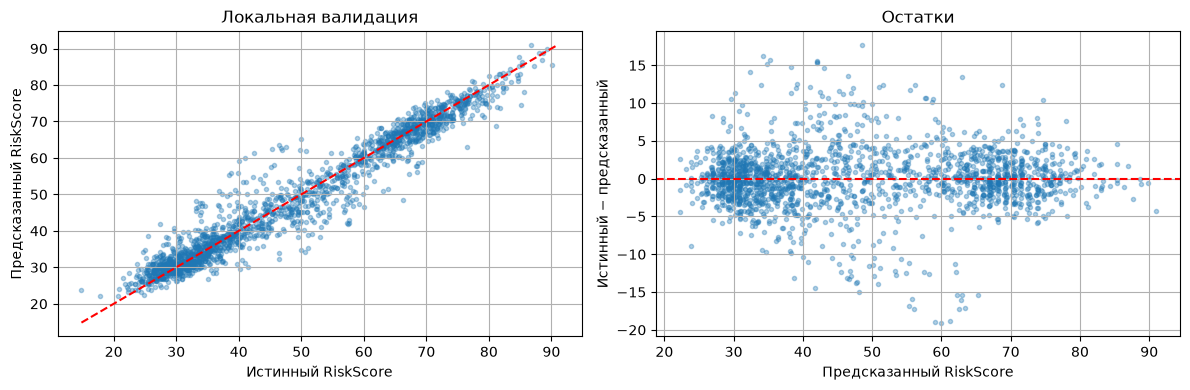

,ID,RiskScore
0,0,33.223186
1,1,53.707245
2,2,30.054304
3,3,34.589055
4,4,32.999712


count    5000.000000
mean       48.183589
std        16.787299
min        22.218549
25%        32.677366
50%        44.205494
75%        64.956299
max        93.695710
Name: RiskScore, dtype: float64

Сохранён файл: submission.csv
MSE локальной валидации: 16.66627316227828
MSE 5-fold: 17.989827712276977


In [12]:
validation_prediction = risk_model.predict(risk_valid_scaled)
residuals = y_valid - validation_prediction
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_valid, validation_prediction, s=9, alpha=0.35)
limits = [min(y_valid.min(), validation_prediction.min()), max(y_valid.max(), validation_prediction.max())]
axes[0].plot(limits, limits, 'r--')
axes[0].set(xlabel='Истинный RiskScore', ylabel='Предсказанный RiskScore', title='Локальная валидация')
axes[1].scatter(validation_prediction, residuals, s=9, alpha=0.35)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set(xlabel='Предсказанный RiskScore', ylabel='Истинный − предсказанный', title='Остатки')
plt.tight_layout()
plt.show()

final_features = RiskFeatures().fit(X)
final_train = final_features.transform(X)
final_test = final_features.transform(test)
final_scaler = Normalizer().fit(final_train)
final_model = LinearRegression(alpha=10).fit(final_scaler.transform(final_train), y)
test_prediction = final_model.predict(final_scaler.transform(final_test))
submission = pd.DataFrame({'ID': test['ID'], 'RiskScore': test_prediction})
assert submission.columns.tolist() == example.columns.tolist()
assert len(submission) == len(test) == len(example)
np.testing.assert_array_equal(submission['ID'], test['ID'])
np.testing.assert_array_equal(submission['ID'], example['ID'])
assert np.isfinite(submission['RiskScore']).all()
submission.to_csv(LAB_DIR / 'submission.csv', index=False)
saved_submission = pd.read_csv(LAB_DIR / 'submission.csv')
np.testing.assert_allclose(saved_submission['RiskScore'], test_prediction)
display(submission.head())
display(submission['RiskScore'].describe())
print('Сохранён файл:', LAB_DIR / 'submission.csv')
print('MSE локальной валидации:', mse(y_valid, validation_prediction))
print('MSE 5-fold:', mse(y, risk_oof))

## 10. Выводы

Свои нормализация, метрики, регрессия и разбиения проверены со sklearn. Дополнительно реализована L2.

| Модель | MSE на валидации |
| --- | ---: |
| Базовая | 49,4958 |
| Полиномиальная с L2 | 24,3030 |
| 19 признаков с L2 | 16,6663 |

MSE итоговой модели по всем прогнозам 5-fold — **17,9898**. На двух фолдах ошибка выше 18; результат скрытого теста пока неизвестен.

В [submission.csv](./submission.csv) сохранено 5000 прогнозов. Отправка на Kaggle ещё не выполнена.
